In [73]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
%matplotlib inline
warnings.filterwarnings('ignore')

In [74]:
#loading dataset

wine_data=pd.read_csv('/content/Lab 22 winequality-red.csv')
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [75]:
wine_data.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [76]:
wine_data.sample()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
503,10.5,0.26,0.47,1.9,0.078,6.0,24.0,0.9976,3.18,1.04,10.9,7


In [77]:
wine_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [78]:
print(wine_data.columns)
print(wine_data.shape)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')
(1599, 12)


In [79]:
#statistical info

wine_data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [80]:
#check for null values
wine_data.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [81]:
#Split the data
x=wine_data.drop(columns='quality')
y=wine_data['quality']

In [82]:
y.value_counts()

,count
quality,
5,681
6,638
7,199
4,53
8,18
3,10


In [83]:
#!pip install imblearn

In [84]:
from imblearn.over_sampling import SMOTE
oversample=SMOTE(k_neighbors=4)

#trasnform the data set
x,y=oversample.fit_resample(x.fillna(0),y)

In [85]:
y.value_counts()

,count
quality,
5,681
6,681
7,681
4,681
8,681
3,681


In [86]:
'''#classify function
from sklearn.model_selection import cross_val_score,train_test_split
def classify(model,x,y):
  x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)
  #train the model
  model.fit(x_train,y_train)
  #return model.score(x_train,y_train)
  print('Accuracy:',model.score(x_test,y_test)*100)
  #score=cross_val_score(model,x,y,cv=5)
  #return score'''

"#classify function\nfrom sklearn.model_selection import cross_val_score,train_test_split\ndef classify(model,x,y):\n  x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)\n  #train the model\n  model.fit(x_train,y_train)\n  #return model.score(x_train,y_train)\n  print('Accuracy:',model.score(x_test,y_test)*100)\n  #score=cross_val_score(model,x,y,cv=5)\n  #return score"

In [87]:

from sklearn.model_selection import train_test_split

def classify(model, x, y):
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.25, random_state=42
    )

    model.fit(x_train, y_train)

    accuracy = model.score(x_test, y_test) * 100
    print('Accuracy:', accuracy)

    return accuracy


**Logisti** **Regression**

In [88]:
#apply logistic regression
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
LogReg_acc=classify(model,x,y)
LogReg_acc

Accuracy: 46.477495107632095


46.477495107632095

**Support** **Vector** **Machine**

In [89]:
from sklearn.svm import SVC
model=SVC(kernel='rbf',random_state=1)
SVM_acc=classify(model,x,y)
SVM_acc

Accuracy: 43.83561643835616


43.83561643835616

**Apply Decsion Tree Classifier**

In [90]:
from sklearn.tree import DecisionTreeClassifier
model=DecisionTreeClassifier()
DecTree_acc=classify(model,x,y)
DecTree_acc

Accuracy: 78.08219178082192


78.08219178082192

**Apply RandomForest Classifier**

In [91]:
from sklearn.tree import DecisionTreeClassifier
model=DecisionTreeClassifier()
Ranfor_acc=classify(model,x,y)
Ranfor_acc

Accuracy: 77.10371819960861


77.10371819960861

In [92]:
Accuracy=[LogReg_acc,DecTree_acc,Ranfor_acc,SVM_acc]
models=['LogisticRegression','DescionTree','RandomForestClassifer','SupportVectorMachine']

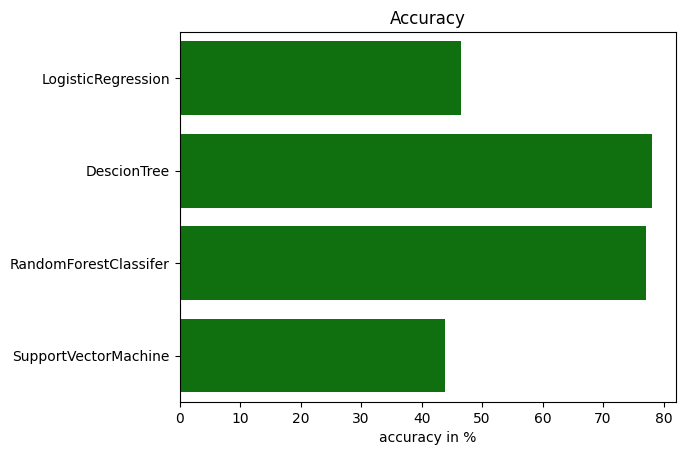

In [93]:
sns.barplot(x=Accuracy,y=models,color='g')
plt.xlabel('accuracy in %')
plt.title('Accuracy')
plt.show()

**Save RandomForest Classifier using Pickle**

In [94]:
from sklearn.ensemble import RandomForestClassifier
RanFor_model=RandomForestClassifier()
RanFor_acc=classify(RanFor_model,x,y)
RanFor_acc

Accuracy: 85.22504892367905


85.22504892367905

In [95]:
import pickle

In [96]:
#save the model to disk
filename='finalRF_model.sav'
pickle.dump(RanFor_model,open(filename,'wb'))

In [97]:
#Load the model back from file
with open(filename,'rb') as file:
  RF_Model=pickle.load(file)

RF_Model

RandomForestClassifier()

In [98]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)

In [99]:
RF_Model.score(x_test,y_test)*100

85.22504892367905